**Problem 1: 3-State MDP**

We have a small MDP where:

1. The agent always chooses Right (fixed policy)
2. S1 → Right → S2 (reward 0)
3. S1 → Left → S1 (reward -1)
4. S2 → Right → S3 (reward +1)
5. S2 → Left → S1 (reward 0)
6. S3 → stays (reward 0)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

class SimpleMDP:
    def __init__(self, gamma=0.9):
        self.states = ['S1', 'S2', 'S3']
        self.actions = ['Left', 'Right']
        self.gamma = gamma
        
    def step(self, state, action):
        if state == 'S1':
            if action == 'Right':
                return 'S2', 0
            else:
                return 'S1', -1
        elif state == 'S2':
            if action == 'Right':
                return 'S3', 1
            else:
                return 'S1', 0
        elif state == 'S3':
            return 'S3', 0
    
    def generate_episode(self, start_state='S1'):
        episode = []
        state = start_state
        
        while True:
            action = 'Right'
            next_state, reward = self.step(state, action)
            episode.append((state, action, reward))
            state = next_state
            if state == 'S3':
                break
        
        return episode

In [2]:
def monte_carlo_prediction_simple(mdp, num_episodes=1000):
    returns = defaultdict(list)
    
    for _ in range(num_episodes):
        episode = mdp.generate_episode()
        G = 0 
        visited = set()
        
        for state, _, reward in reversed(episode):
            G = reward + mdp.gamma * G 
            
            if state not in visited:
                returns[state].append(G)
                visited.add(state)
    
    value_func = {}
    for state in mdp.states:
        if state in returns:
            value_func[state] = np.mean(returns[state])
        else:
            value_func[state] = 0.0
    
    return value_func, returns

In [3]:
mdp1 = SimpleMDP(gamma=0.9)
value_func1, returns1 = monte_carlo_prediction_simple(mdp1, num_episodes=1000)

print("=" * 50)
print("PROBLEM 1: Estimated Value Function")
print("=" * 50)
for state in ['S1', 'S2', 'S3']:
    print(f"V({state}) = {value_func1[state]:.4f}")

print(f"\nVisit counts per state:")
for state in ['S1', 'S2', 'S3']:
    print(f"  {state}: {len(returns1[state])} times")

PROBLEM 1: Estimated Value Function
V(S1) = 0.9000
V(S2) = 1.0000
V(S3) = 0.0000

Visit counts per state:
  S1: 1000 times
  S2: 1000 times
  S3: 0 times


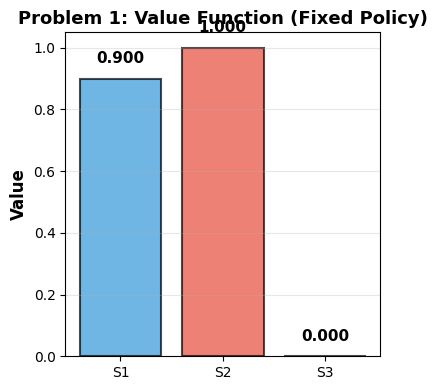

In [4]:
fig1 = plt.figure(figsize=(4,4))
states = ['S1', 'S2', 'S3']
values = [value_func1[s] for s in states]
colors = ['#3498db', '#e74c3c', '#2ecc71']
plt.bar(states, values, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)
plt.ylabel('Value', fontsize=12, fontweight='bold')
plt.title('Problem 1: Value Function (Fixed Policy)', fontsize=13, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.ylim(bottom=0)

for i, (state, val) in enumerate(zip(states, values)):
    plt.text(i, val + 0.05, f'{val:.3f}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

**Problem 2: 4×4 Gridworld**

1. Grid: 4×4 cells (16 states total)
2. Start: S0 (top-left)
3. Terminal: S15 (bottom-right, reward +10)
4. Stochastic transitions: 80% intended direction, 20% random direction
5. Hitting boundary: stay in place, reward -1
6. Random policy: uniform action selection

In [5]:
class Gridworld:
    def __init__(self, grid_size=4, gamma=0.95):
        self.grid_size = grid_size
        self.num_states = grid_size * grid_size
        self.gamma = gamma
        self.start_state = 0
        self.terminal_state = self.num_states - 1
        
    def state_to_pos(self, state):
        return (state // self.grid_size, state % self.grid_size)
    
    def pos_to_state(self, row, col):
        if 0 <= row < self.grid_size and 0 <= col < self.grid_size:
            return row * self.grid_size + col
        return None
    
    def step(self, state, action):
        if state == self.terminal_state:
            return self.terminal_state, 0, True
        
        row, col = self.state_to_pos(state)
        
        # 80% success, 20% random other direction
        if np.random.rand() < 0.8:
            deltas = [(-1, 0), (1, 0), (0, -1), (0, 1)]
            dr, dc = deltas[action]
        else:
            other_actions = [a for a in range(4) if a != action]
            random_action = np.random.choice(other_actions)
            deltas = [(-1, 0), (1, 0), (0, -1), (0, 1)]
            dr, dc = deltas[random_action]
        
        new_row, new_col = row + dr, col + dc
        
        # Boundary check
        if not (0 <= new_row < self.grid_size and 0 <= new_col < self.grid_size):
            return state, -1, False
        
        next_state = self.pos_to_state(new_row, new_col)
        
        if next_state == self.terminal_state:
            return next_state, 10, True
        else:
            return next_state, 0, False
    
    def generate_episode(self):
        episode = []
        state = self.start_state
        
        while True:
            action = np.random.randint(0, 4)
            next_state, reward, is_terminal = self.step(state, action)
            episode.append((state, action, reward))
            state = next_state
            
            if is_terminal:
                break
        
        return episode

In [6]:
def monte_carlo_prediction_gridworld(gridworld, num_episodes=10000):
    returns = defaultdict(list)
    
    for _ in range(num_episodes):
        episode = gridworld.generate_episode()
        G = 0
        visited = set()
        
        for state, _, reward in reversed(episode):
            G = reward + gridworld.gamma * G
            if state not in visited:
                returns[state].append(G)
                visited.add(state)
    
    # Average returns
    value_func = np.zeros(gridworld.num_states)
    for state in range(gridworld.num_states):
        if state in returns:
            value_func[state] = np.mean(returns[state])
    
    return value_func, returns

In [7]:
gridworld = Gridworld(grid_size=4, gamma=0.95)
value_func2, returns2 = monte_carlo_prediction_gridworld(gridworld, num_episodes=10000)

print("\n" + "=" * 50)
print("PROBLEM 2: 4×4 Gridworld Value Function")
print("=" * 50)

# Display as grid
for i in range(4):
    for j in range(4):
        state = i * 4 + j
        print(f"{value_func2[state]:7.3f}", end="  ")
    print()


PROBLEM 2: 4×4 Gridworld Value Function
  1.377    2.245    2.928    3.069  
  2.300    3.605    4.723    5.059  
  2.928    4.632    6.509    7.740  
  3.041    5.016    7.721    0.000  


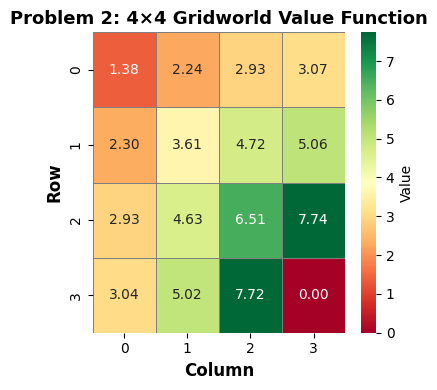

In [8]:
fig2 = plt.figure(figsize=(4, 4))
value_grid = value_func2.reshape(4, 4)
sns.heatmap(value_grid, annot=True, fmt='.2f', cmap='RdYlGn', 
            cbar_kws={'label': 'Value'}, linewidths=0.5, linecolor='gray')
plt.title('Problem 2: 4×4 Gridworld Value Function', fontsize=13, fontweight='bold')
plt.xlabel('Column', fontsize=12, fontweight='bold')
plt.ylabel('Row', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()